In [29]:
#pip install scikit-learn

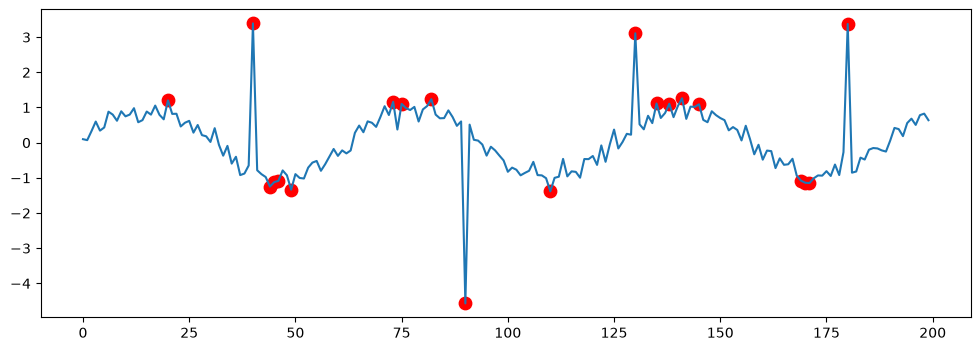

In [30]:
from sklearn.ensemble import IsolationForest

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

t = np.arange(200)
serie = np.sin(t/10)+np.random.normal(0,0.2,200)

serie[[40,90,130,180]] += [4,-5,3,4]

modelo = IsolationForest(
    contamination=0.1,
    random_state=42
)

labels = modelo.fit_predict(serie.reshape(-1,1))

plt.figure(figsize=(12,4))
plt.plot(serie)

plt.scatter(
    np.where(labels==-1),
    serie[labels==-1],
    color="red",
    s=80
)

plt.show()

In [36]:
import numpy as np
import pandas as pd

def hampel_filter(x, window_size=7, n_sigma=3):
    x = pd.Series(x)

    rolling_median = x.rolling(
        window=2*window_size+1,
        center=True
    ).median()

    diff = np.abs(x - rolling_median)

    mad = diff.rolling(
        window=2*window_size+1,
        center=True
    ).median()

    threshold = n_sigma * 1.4826 * mad

    outliers = diff > threshold

    return outliers

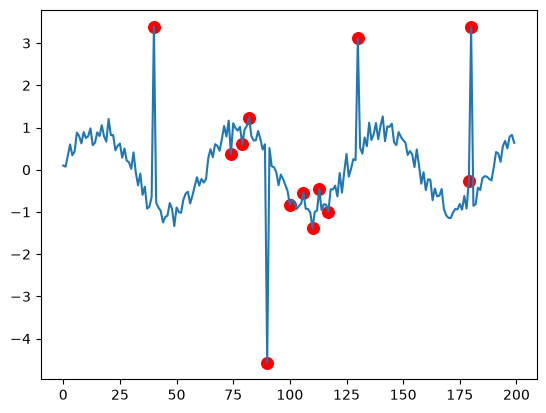

In [37]:
mask = hampel_filter(serie)

plt.plot(serie)

plt.scatter(
    np.where(mask),
    serie[mask],
    color="red",
    s=70
)

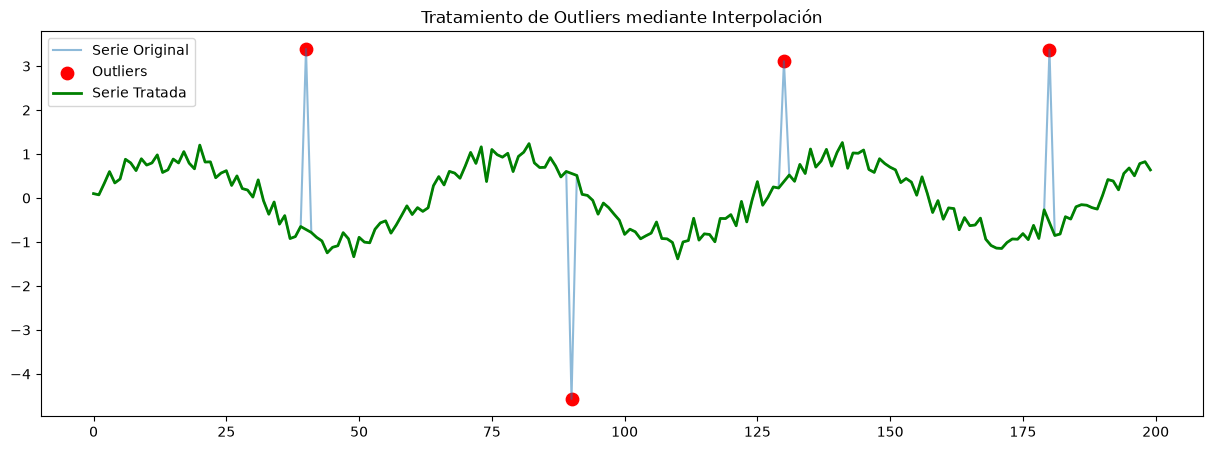

In [38]:
from sklearn.ensemble import IsolationForest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Generar serie
# -------------------------
np.random.seed(42)

t = np.arange(200)
serie = np.sin(t/10) + np.random.normal(0, 0.2, 200)

# Agregar outliers
serie[[40, 90, 130, 180]] += [4, -5, 3, 4]

# -------------------------
# Detectar outliers
# -------------------------
modelo = IsolationForest(
    contamination=0.02,
    random_state=42
)

labels = modelo.fit_predict(serie.reshape(-1,1))

# True donde hay outliers
mask = labels == -1

# -------------------------
# Reemplazar outliers por NaN
# -------------------------
serie_limpia = pd.Series(serie.copy())

serie_limpia[mask] = np.nan

# -------------------------
# Interpolar
# -------------------------
serie_interpolada = serie_limpia.interpolate(method="linear")

# -------------------------
# Graficar
# -------------------------
plt.figure(figsize=(15,5))

plt.plot(serie, label="Serie Original", alpha=0.5)

plt.scatter(
    np.where(mask),
    serie[mask],
    color="red",
    s=80,
    label="Outliers"
)

plt.plot(
    serie_interpolada,
    color="green",
    linewidth=2,
    label="Serie Tratada"
)

plt.legend()
plt.title("Tratamiento de Outliers mediante Interpolación")
plt.show()

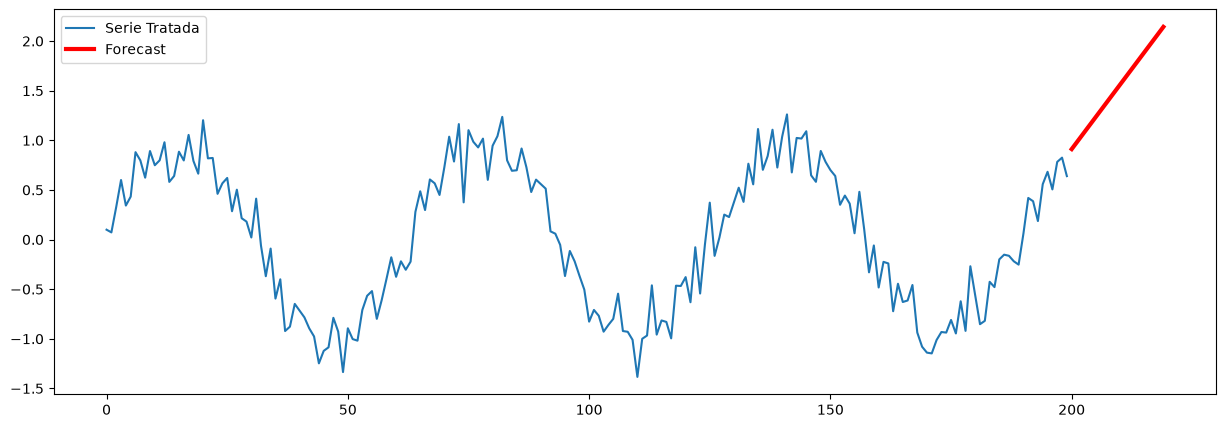

In [34]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

modelo = ExponentialSmoothing(
    serie_interpolada,
    trend="add",
    seasonal=None
)

fit = modelo.fit()

forecast = fit.forecast(20)

plt.figure(figsize=(15,5))

plt.plot(serie_interpolada, label="Serie Tratada")

plt.plot(
    range(len(serie_interpolada),
          len(serie_interpolada)+20),
    forecast,
    color="red",
    linewidth=3,
    label="Forecast"
)

plt.legend()
plt.show()

In [35]:
serie_mediana = pd.Series(serie.copy())

ventana = 5

for idx in np.where(mask)[0]:
    inicio = max(0, idx-ventana)
    fin = min(len(serie), idx+ventana+1)

    mediana = np.median(serie[inicio:fin])

    serie_mediana.iloc[idx] = mediana